## Problem 1.1 First-order NH₃ decomposition


System: Rigid, well-mixed, isothermal gas-phase batch vessel 2NH₃ → N₂ + 3H₂. Track NH₃ only.

Data: V = 0.010 m³, T = 700 K, -r_NH₃ = k C_NH₃, k = 8.0×10⁻³ s⁻¹

Initial condition: N_NH₃(0) = 0.50 mol

Assumptions: Constant V and T. Irreversible.
 # Tasks:

Write the NH₃ mole balance with notation and dimensions for every term.

Solve over 0 to 600 s.

Derive the analytical solution and compare.

Find the half-life from your numerical solution.

Expected ODEs: 1

Plot: N_NH₃ vs t (numerical and analytical), absolute error vs t

Project link: solve_ivp signature and passing parameters to the right-hand side.

The numericalconcentration of NH3 at t = 600 s is: 0.4125628094920595 mol/m^3
The analyticalconcentration of NH3 at t = 600 s is: 0.4114873524510015 mol/m^3


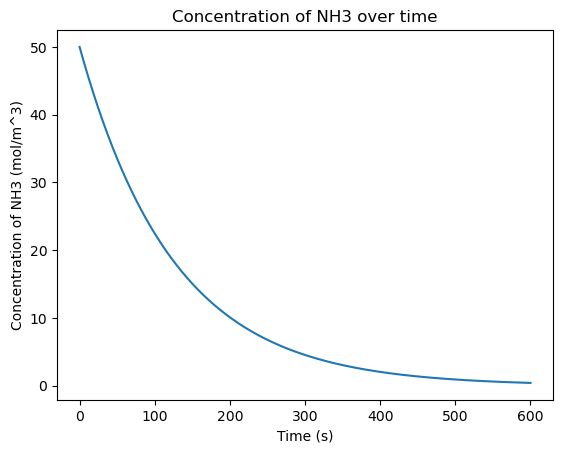

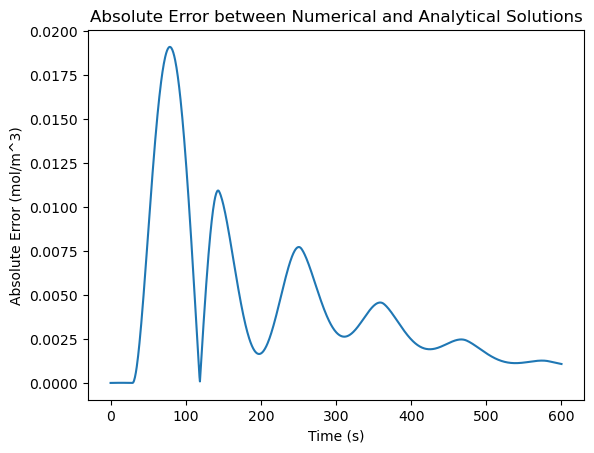

In [38]:
#Numerical solution of the first order reaction: NH3 -> 1/2 N2 + 3/2 H2

from scipy.integrate import solve_ivp

n_NH3_initial = 0.50 #mol
V = 0.010 #m^3
T = 700 #K
R = 8.314 #J/(mol*K)
k = 0.008 #s^-1
t0 = 0 #s
t = 600 #s
c_NH3_initial = n_NH3_initial / V #mol/m^3

def reaction(t, c):
    dc_NH3_dt = -k*c
    return [dc_NH3_dt]
sol = solve_ivp(reaction, [t0, t], [c_NH3_initial], t_eval=[t])
# print(sol.t)
print("The numericalconcentration of NH3 at t = " + str(t) + " s is:", sol.y[0][-1], "mol/m^3")


#Analytical solution of the first order reaction: NH3 -> 1/2 N2 + 3/2 H2

import numpy as np

n_NH3_initial = 0.50 #mol
V = 0.010 #m^3
c_NH3_initial = n_NH3_initial / V #mol/m^3
t0 = 0 #s
t = 600 #s
k = 0.008 #s^-1
c_NH3 = -k*t + np.log(c_NH3_initial) 
print ("The analyticalconcentration of NH3 at t = " + str(t) + " s is:", np.exp(c_NH3), "mol/m^3")


#Plotting the concentration of NH3 over time
import matplotlib.pyplot as plt
t_values = np.linspace(t0, t, 1000)
c_NH3_values = c_NH3_initial * np.exp(-k*t_values)
plt.plot(t_values, c_NH3_values)
plt.xlabel('Time (s)')
plt.ylabel('Concentration of NH3 (mol/m^3)')
plt.title('Concentration of NH3 over time')


#Plotting the absolute error between numerical and analytical solutions
t_values = np.linspace(t0, t, 1000)
c_NH3_numerical = solve_ivp(reaction, [t0, t], [c_NH3_initial], t_eval=t_values).y[0]
c_NH3_analytical = c_NH3_initial * np.exp(-k*t_values)
absolute_error = np.abs(c_NH3_numerical - c_NH3_analytical)
plt.figure()
plt.plot(t_values, absolute_error)
plt.xlabel('Time (s)')
plt.ylabel('Absolute Error (mol/m^3)')
plt.title('Absolute Error between Numerical and Analytical Solutions')
plt.show()

## Problem 1.2 Second-order decomposition and solver behaviour

System: Same vessel and initial condition as 1.1.

Data: -r_NH₃ = k C_NH₃², k = 2.0×10⁻⁴ m³ mol⁻¹ s⁻¹

 # Tasks:

1. Write dC/dt = -kC² and check the dimensions of both sides.

2. Solve with solve_ivp as in 1.1.

3. Derive the analytical solution. Use it to find the time for 90% conversion.

4. Plot numerical and analytical C on one axis.

5. Compute the absolute error at your plotted times.

6. Re-solve with rtol = 1e-6 and atol = 1e-12. Compare the maximum error with task 5.

7. Repeat for rtol from 10⁻² to 10⁻¹⁰. Record maximum error and sol.nfev. Plot error against rtol on log axes.

8. Repeat task 7 with default atol. Compare the two plots.

9. Optional: compare t_eval with dense_output=True at the same times.


The concentration of NH3 at t = 1500 s is: 3.13063883172756 mol/m^3
The maximum error between numerical and analytical solutions is: 0.01908882397082934 %
The concentration of NH3 at t = 1500 s is: 3.125 mol/m^3
The time for 90% conversion of NH3 is: 1000.0 s


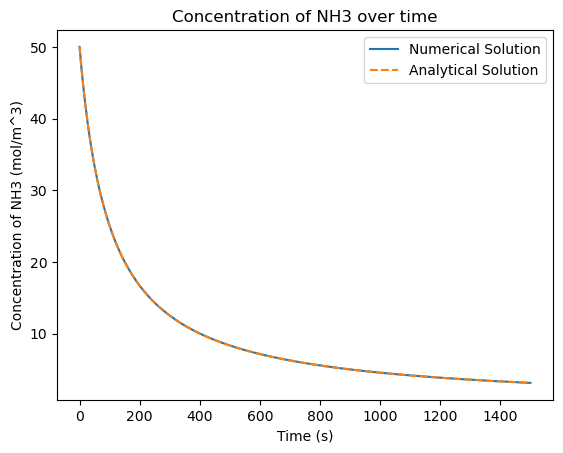

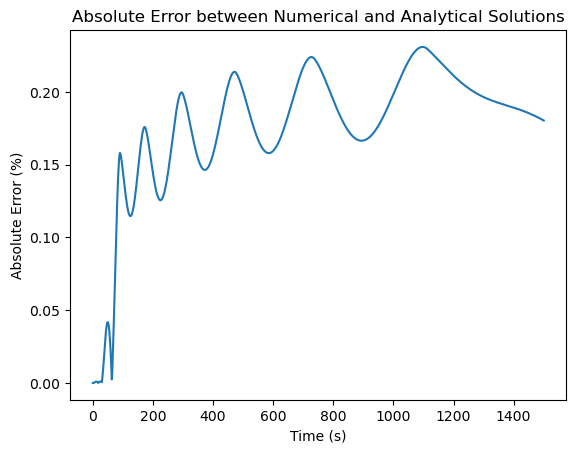

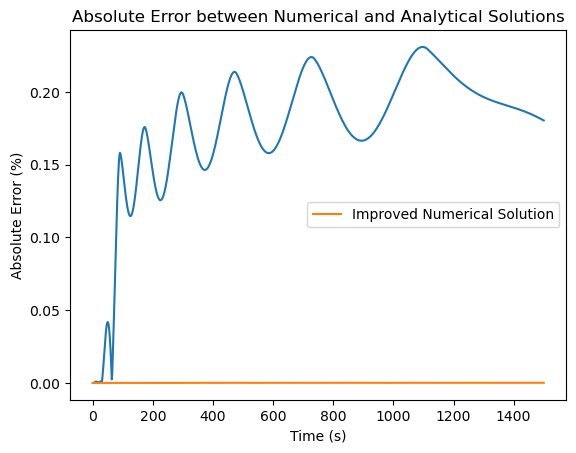

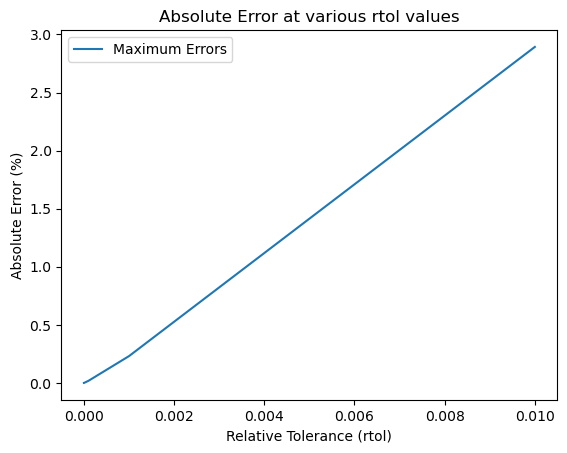

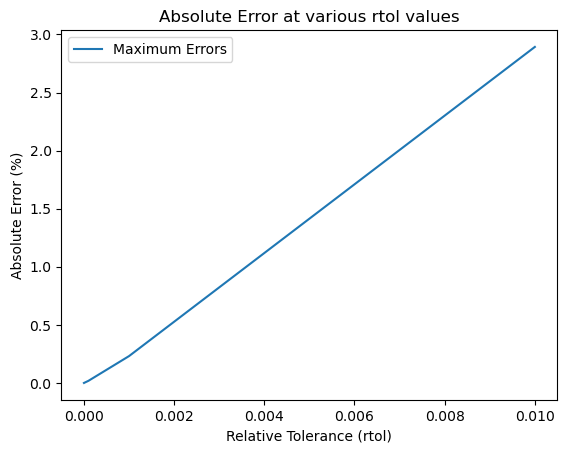

In [39]:
#Solving numerically

n_NH3_initial = 0.50 #mol
V = 0.010 #m^3
c_NH3_initial = n_NH3_initial / V #mol/m^3
t0 = 0 #s
t = 1500 #s
k = 2*10**(-4 ) #m^3/(mol*s)
def reaction2(t, c):
    dc_NH3_dt = -k*c**2
    return [dc_NH3_dt]
sol2 = solve_ivp(reaction2, [t0, t], [c_NH3_initial], t_eval=[t])
print ("The concentration of NH3 at t = " + str(t) + " s is:", sol2.y[0][-1], "mol/m^3")
max_error = np.max(absolute_error)
print ("The maximum error between numerical and analytical solutions is:", max_error, "%")

#Solving analytically & finding the time for 90% conversion of NH3
c_NH3_analytical = (k*t + (1/c_NH3_initial))**(-1)
print ("The concentration of NH3 at t = " + str(t) + " s is:", c_NH3_analytical, "mol/m^3")

t_90 = (1/(0.1*c_NH3_initial)/k)
print ("The time for 90% conversion of NH3 is:", t_90, "s")

#Plotting numerical and analytical solutions
t_values = np.linspace(t0, t, 1000)
c_NH3_numerical = solve_ivp(reaction2, [t0, t], [c_NH3_initial], t_eval=t_values).y[0]
c_NH3_analytical = (k*t_values + (1/c_NH3_initial))**(-1)
plt.figure()
plt.plot(t_values, c_NH3_numerical, label='Numerical Solution')
plt.plot(t_values, c_NH3_analytical, label='Analytical Solution', linestyle='dashed')
plt.xlabel('Time (s)')
plt.ylabel('Concentration of NH3 (mol/m^3)')
plt.title('Concentration of NH3 over time')
plt.legend()


#Plotting the absolute error between numerical and analytical solutions as a percentage of the analytical solution
absolute_error = np.abs((c_NH3_numerical - c_NH3_analytical)/c_NH3_analytical) * 100
plt.figure()
plt.plot(t_values, absolute_error)
plt.xlabel('Time (s)')
plt.ylabel('Absolute Error (%)')
plt.title('Absolute Error between Numerical and Analytical Solutions')
plt.show()

#Re-solve numerically with atol = 1e-12 and rtol = 1e-6 & compare the maximum error with the previous solution
C_NH3_numerical2 = solve_ivp(reaction2, [t0, t], [c_NH3_initial], t_eval=t_values, atol=1e-12, rtol=1e-6).y[0]
absolute_error2 = np.abs((C_NH3_numerical2 - c_NH3_analytical)/c_NH3_analytical) * 100
plt.figure()
plt.plot(t_values, absolute_error)
plt.plot(t_values, absolute_error2, label='Improved Numerical Solution')
plt.xlabel('Time (s)')
plt.ylabel('Absolute Error (%)')
plt.title('Absolute Error between Numerical and Analytical Solutions')
plt.legend()
plt.show()

#Re-solving at rtol varying from 1e-2 to 1e-10 & plotting error vs rtol
rtols = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
max_errors = []
for rtol in rtols:
    
    C_NH3_numerical3 = solve_ivp(reaction2, [t0, t], [c_NH3_initial], t_eval=t_values, atol=1e-12, rtol=rtol).y[0]
    absolute_error3 = np.abs((C_NH3_numerical3 - c_NH3_analytical)/c_NH3_analytical) * 100
    max_errors.append(np.max(absolute_error3))
    
plt.figure()
plt.plot(rtols, max_errors, label='Maximum Errors')
plt.xlabel('Relative Tolerance (rtol)')
plt.ylabel('Absolute Error (%)')
plt.title('Absolute Error at various rtol values')
plt.legend()
plt.show()

#Re-solving at the standard atol value of 1e-6 & varying rtol from 1e-2 to 1e-10 & plotting error vs rtol
rtols = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
max_errors = []
for rtol in rtols:
    
    C_NH3_numerical3 = solve_ivp(reaction2, [t0, t], [c_NH3_initial], t_eval=t_values, rtol=rtol).y[0]
    absolute_error3 = np.abs((C_NH3_numerical3 - c_NH3_analytical)/c_NH3_analytical) * 100
    max_errors.append(np.max(absolute_error3))
    
plt.figure()
plt.plot(rtols, max_errors, label='Maximum Errors')
plt.xlabel('Relative Tolerance (rtol)')
plt.ylabel('Absolute Error (%)')
plt.title('Absolute Error at various rtol values')
plt.legend()
plt.show()